# 04: Preprocess modalities

In [1]:
import spatialdata as sd
import spatialdata_plot
from pathlib import Path
import scanpy as sc
import scanpy.external as sce
import anndata as ad
import pandas as pd
from spatialdata.models import TableModel

import pycytominer
from pycytominer.operations import RobustMAD

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/importlib/__init__.py:126: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  return _bootstrap._gcd_import(name[level:], package, level)


## 04A: Get data

In [2]:
proj_dir = Path("/lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure")
data_dir = proj_dir / Path("data")
halfbrain_path = data_dir / Path("halfbrain_sdata_celltypes.zarr")
quarterbrain_path = data_dir / Path("quarterbrain_sdata_celltypes.zarr")
quarterbrain_morphology_path = data_dir / Path("quarterbrain_sdata_measured.zarr")

In [3]:
sdata_quarter = sd.read_zarr(quarterbrain_path)
sdata_quarter_morphology = sd.read_zarr(quarterbrain_morphology_path)

sdata_half = sd.read_zarr(halfbrain_path)

version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kw

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
version mismatch: detected: RasterFormatV02, requested: FormatV04
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor

In [4]:
sdata_quarter

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/quarterbrain_sdata_celltypes.zarr
├── Images
│     └── 'stitched_image': DataTree[cyx] (5, 25589, 46923), (5, 12794, 23461), (5, 6397, 11730), (5, 3198, 5865), (5, 1599, 2932)
├── Labels
│     └── 'segmentation': DataTree[yx] (25589, 46923), (12794, 23461), (6397, 11730), (3198, 5865), (1599, 2932)
├── Points
│     └── 'points': DataFrame with shape: (<Delayed>, 12) (3D points)
└── Tables
      └── 'gexp': AnnData (38996, 960)
with coordinate systems:
    ▸ 'global', with elements:
        stitched_image (Images), segmentation (Labels), points (Points)

In [5]:
sdata_half

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/halfbrain_sdata_celltypes.zarr
├── Images
│     └── 'stitched_image': DataTree[cyx] (5, 59881, 46914), (5, 29940, 23457), (5, 14970, 11728), (5, 7485, 5864), (5, 3742, 2932)
├── Labels
│     └── 'segmentation': DataTree[yx] (59881, 46914), (29940, 23457), (14970, 11728), (7485, 5864), (3742, 2932)
├── Points
│     └── 'points': DataFrame with shape: (<Delayed>, 12) (3D points)
└── Tables
      └── 'gexp': AnnData (48556, 960)
with coordinate systems:
    ▸ 'global', with elements:
        stitched_image (Images), segmentation (Labels), points (Points)

### Load and merge morphology
Had to divide and conquer here. Quarterbrain ran through on the entire object, had to split halfbrain across scripts/nodes. Now aggregating for coherent downstream analysis

In [6]:
# halfbrain: load raw features

halfbrain_morpho_cpm_core_df = pd.read_csv(data_dir / Path("halfbrain_morpho_cpm_core.csv"), index_col=0)
halfbrain_morpho_cpm_corr_df = pd.read_csv(data_dir / Path("halfbrain_morpho_cpm_corr.csv"), index_col=0)
halfbrain_morpho_ski_labels_df = pd.read_csv(data_dir / Path("halfbrain_morpho_labels.csv"), index_col=0)
halfbrain_morpho_ski_labelsimg_df = pd.read_csv(data_dir / Path("halfbrain_morpho_label_images.csv"), index_col=0)


halfbrain_morphology_df = pd.concat([
    halfbrain_morpho_cpm_core_df,
    halfbrain_morpho_cpm_corr_df,
    halfbrain_morpho_ski_labels_df,
    halfbrain_morpho_ski_labelsimg_df,
], axis=1)

# adjust index to match sdata obj
halfbrain_morphology_df.index -= 1

halfbrain_morphology_df

,intensity_mean_0,intensity_min_0,intensity_std_0,intensity_max_0,RadialDistribution_FracAtD_1of4_0,RadialDistribution_MeanFrac_1of4_0,RadialDistribution_RadialCV_1of4_0,RadialDistribution_FracAtD_2of4_0,RadialDistribution_MeanFrac_2of4_0,RadialDistribution_RadialCV_2of4_0,...,intensity_mean_2,intensity_min_2,intensity_min_3,intensity_max_3,intensity_std_3,intensity_mean_3,intensity_max_4,intensity_min_4,intensity_mean_4,intensity_std_4
0,11261.514362,1994.0,9773.225968,51724.0,0.037333,1.034963,0.826823,0.122667,0.956417,0.445921,...,190.413494,105.0,404.0,3728.0,346.683141,1030.281229,4031.0,164.0,283.033400,250.751174
1,12621.618812,3858.0,7477.937146,44956.0,0.187948,10.630359,0.475140,0.268293,3.951728,0.605407,...,205.387553,117.0,385.0,1958.0,289.494621,1015.722772,1103.0,147.0,198.165488,63.821906
2,24464.665313,5157.0,12608.724865,55126.0,0.332209,8.115032,0.616723,0.209106,1.360041,0.642025,...,116.952812,82.0,160.0,1580.0,142.295043,284.450000,2401.0,151.0,220.856875,126.541012
3,16497.308370,4564.0,7015.208408,36370.0,0.119584,3.490146,0.733133,0.346620,2.622761,0.733746,...,344.450318,131.0,391.0,3447.0,277.588835,914.905042,4077.0,147.0,242.952521,153.330640
4,15256.513260,3807.0,10210.673267,43345.0,0.119217,3.176099,0.497688,0.338078,2.394884,0.509664,...,389.685027,126.0,283.0,2954.0,222.577376,694.238678,3367.0,168.0,275.331293,133.450469
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48551,5365.228893,1733.0,3142.899108,17293.0,0.245455,5.567118,0.991116,0.269091,1.667738,0.693111,...,385.402439,168.0,275.0,1125.0,92.044187,356.893996,1702.0,231.0,459.498124,198.451209
48552,7257.030882,3242.0,2493.227839,13887.0,0.409449,9.600869,0.544994,0.041995,0.246176,0.415104,...,191.555882,125.0,393.0,1781.0,235.188140,648.792647,410.0,184.0,231.317647,21.796903
48553,32159.171991,5566.0,18791.114541,65532.0,0.448198,10.241329,0.708939,0.346847,2.344808,0.429003,...,600.680963,153.0,241.0,1008.0,104.741643,394.469584,766.0,147.0,192.563676,39.495428
48554,29649.477240,6021.0,14032.101186,55466.0,0.034537,0.683928,0.778129,0.357928,2.070973,0.753833,...,514.835704,151.0,241.0,754.0,72.830152,380.141536,409.0,151.0,186.017781,25.101424


In [7]:
# halfbrain: create adata that also contains celltype info

adata_half_morphology = ad.AnnData(
    halfbrain_morphology_df,
    obs=sdata_half.tables["gexp"].obs,
)

# use NanoString cell_barcode as index (is unique, needed for concat later)
adata_half_morphology.obs_names = adata_half_morphology.obs["cell_barcode"].astype(str)

adata_half_morphology

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 48556 × 1739
    obs: 'fov_x', 'cellID', 'global_cell_id', 'x_global_px', 'y_global_px', 'x_local_px', 'y_local_px', 'region', 'cell_barcode', 'cluster', 'cluster_long', 'tissue', 'run_tissue', 'fov_y', 'x_fov_px', 'y_fov_px'

In [8]:
# quarterbrain

adata_quarter_morphology = sdata_quarter_morphology.tables["morphology"]
adata_quarter_morphology.obs = sdata_quarter.tables["gexp"].obs

# use NanoString cell_barcode as index (is unique, needed for concat later)
adata_quarter_morphology.obs_names = adata_quarter_morphology.obs["cell_barcode"].astype(str)

adata_quarter_morphology

AnnData object with n_obs × n_vars = 38996 × 1739
    obs: 'fov_x', 'cellID', 'global_cell_id', 'x_global_px', 'y_global_px', 'x_local_px', 'y_local_px', 'region', 'cell_barcode', 'cluster', 'cluster_long', 'tissue', 'run_tissue', 'fov_y', 'x_fov_px', 'y_fov_px'
    uns: 'spatialdata_attrs'

In [9]:
# Are var_names unique?
print(adata_quarter_morphology.var_names.is_unique)  # likely False
print(adata_half_morphology.var_names  .is_unique)  # likely False

# Count how many duplicates there are:
n_dupes_q = adata_quarter_morphology.var_names.duplicated().sum()
n_dupes_h = adata_half_morphology.var_names  .duplicated().sum()
print(f"Quarter has {n_dupes_q} duplicate names")
print(f"Half    has {n_dupes_h} duplicate names")

# See which names are duplicated in each
dupes_q = adata_quarter_morphology.var_names[
    adata_quarter_morphology.var_names.duplicated()
]
dupes_h = adata_half_morphology.var_names[
    adata_half_morphology.var_names.duplicated()
]
print("Duplicates in quarter:", sorted(set(dupes_q)))
print("Duplicates in half   :", sorted(set(dupes_h)))


False
False
Quarter has 20 duplicate names
Half    has 20 duplicate names
Duplicates in quarter: ['intensity_max_0', 'intensity_max_1', 'intensity_max_2', 'intensity_max_3', 'intensity_max_4', 'intensity_mean_0', 'intensity_mean_1', 'intensity_mean_2', 'intensity_mean_3', 'intensity_mean_4', 'intensity_min_0', 'intensity_min_1', 'intensity_min_2', 'intensity_min_3', 'intensity_min_4', 'intensity_std_0', 'intensity_std_1', 'intensity_std_2', 'intensity_std_3', 'intensity_std_4']
Duplicates in half   : ['intensity_max_0', 'intensity_max_1', 'intensity_max_2', 'intensity_max_3', 'intensity_max_4', 'intensity_mean_0', 'intensity_mean_1', 'intensity_mean_2', 'intensity_mean_3', 'intensity_mean_4', 'intensity_min_0', 'intensity_min_1', 'intensity_min_2', 'intensity_min_3', 'intensity_min_4', 'intensity_std_0', 'intensity_std_1', 'intensity_std_2', 'intensity_std_3', 'intensity_std_4']


In [10]:
adata_quarter_morphology.var_names_make_unique()
adata_half_morphology.var_names_make_unique()

In [11]:
adata_quarter_morphology.to_df().loc[:, ['intensity_max_0', 'intensity_max_1-1']]

,intensity_max_0,intensity_max_1-1
cell_barcode,,
c_1_1_1,39.0,16.0
c_1_1_2,24.0,127.0
c_1_1_3,46.0,121.0
c_1_1_4,21.0,212.0
c_1_1_5,42.0,179.0
...,...,...
c_1_66_710,164.0,36.0
c_1_66_711,29.0,60.0
c_1_66_712,110.0,172.0


Okay, they have different values. We'll keep both and let the preproc figure it out

In [12]:
# write morphology adata to disk

adata_morphology_raw = ad.concat([adata_half_morphology, adata_quarter_morphology])
adata_morphology_raw.write(data_dir / "adata_morphology_raw.h5ad")
adata_morphology_raw

AnnData object with n_obs × n_vars = 87552 × 1739
    obs: 'fov_x', 'cellID', 'global_cell_id', 'x_global_px', 'y_global_px', 'x_local_px', 'y_local_px', 'region', 'cell_barcode', 'cluster', 'cluster_long', 'tissue', 'run_tissue', 'fov_y', 'x_fov_px', 'y_fov_px'

### Load and merge gexp

In [13]:
adata_gexp_raw = ad.concat([sdata_half.tables["gexp"], sdata_quarter.tables["gexp"]])

adata_gexp_raw.write(data_dir / "adata_gexp_raw.h5ad")
adata_gexp_raw

AnnData object with n_obs × n_vars = 87552 × 960
    obs: 'fov_x', 'cellID', 'global_cell_id', 'x_global_px', 'y_global_px', 'x_local_px', 'y_local_px', 'region', 'cell_barcode', 'cluster', 'cluster_long', 'tissue', 'run_tissue', 'fov_y', 'x_fov_px', 'y_fov_px'
    obsm: 'spatial'

## Preprocessing

### Gene expression: Run Scanpy workflow
following https://scanpy.readthedocs.io/en/stable/tutorials/basics/clustering.html

In [14]:
adata_gexp_raw.var["mt"] = adata_gexp_raw.var_names.str.startswith("MT-")
adata_gexp_raw.var["ribo"] = adata_gexp_raw.var_names.str.startswith(("RPS", "RPL"))
adata_gexp_raw.var["hb"] = adata_gexp_raw.var_names.str.contains("^HB[^(P)]")

In [15]:
sc.pp.calculate_qc_metrics(
    adata_gexp_raw,
    qc_vars=["mt", "ribo", "hb"],
    inplace=True,
    log1p=True,
)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:432: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


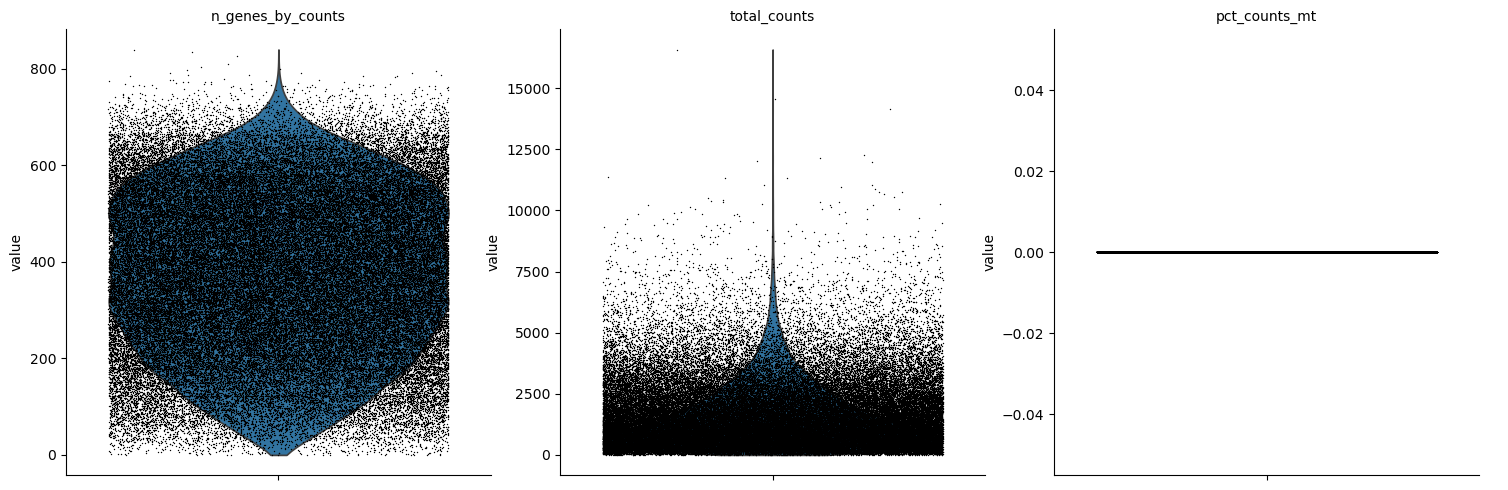

In [16]:
sc.pl.violin(
    adata_gexp_raw,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

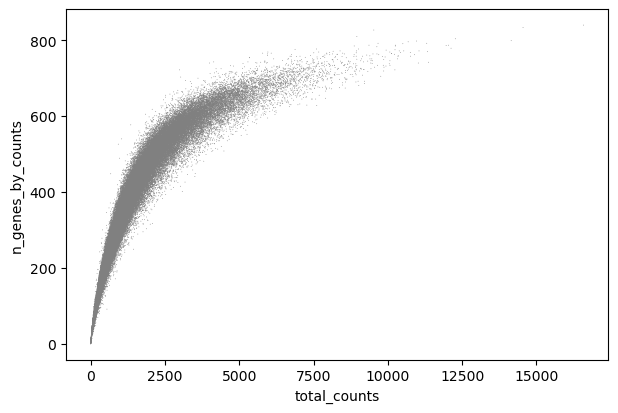

In [17]:
sc.pl.scatter(adata_gexp_raw, "total_counts", "n_genes_by_counts")

In [18]:

print(adata_gexp_raw.shape)

# not doing this step because our resulting data is then out of sync when we merge with morphology
# sc.pp.filter_cells(adata_gexp_raw, min_genes=100) # only cells with at least 100 genes expressed

sc.pp.filter_genes(adata_gexp_raw, min_cells=100) # only genes expressed in at least 100 cells
print(adata_gexp_raw.shape)

(87552, 960)


(87552, 960)


In [19]:
adata_gexp_raw.layers["counts"] = adata_gexp_raw.X.copy()
sc.pp.normalize_total(sdata_quarter.tables["gexp"])
sc.pp.log1p(adata_gexp_raw)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/scanpy/preprocessing/_normalization.py:234: UserWarning: Some cells have zero counts
  warn(UserWarning("Some cells have zero counts"))


#### Subset to HVGs

In [20]:
sc.pp.highly_variable_genes(adata_gexp_raw, flavor="seurat", batch_key="tissue")
adata_gexp_hvg = adata_gexp_raw[:, adata_gexp_raw.var["highly_variable"]].copy()
adata_gexp_hvg

AnnData object with n_obs × n_vars = 87552 × 181
    obs: 'fov_x', 'cellID', 'global_cell_id', 'x_global_px', 'y_global_px', 'x_local_px', 'y_local_px', 'region', 'cell_barcode', 'cluster', 'cluster_long', 'tissue', 'run_tissue', 'fov_y', 'x_fov_px', 'y_fov_px', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'log1p', 'hvg'
    obsm: 'spatial'
    layers: 'c

#### Integrate

In [21]:
sc.tl.pca(adata_gexp_hvg)
sce.pp.harmony_integrate(adata_gexp_hvg, key="tissue", max_iter_harmony=20)

2025-05-18 18:51:46,566 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...


2025-05-18 18:51:54,885 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-05-18 18:51:55,303 - harmonypy - INFO - Iteration 1 of 20
2025-05-18 18:52:48,576 - harmonypy - INFO - Iteration 2 of 20
2025-05-18 18:53:37,480 - harmonypy - INFO - Iteration 3 of 20
2025-05-18 18:54:31,641 - harmonypy - INFO - Iteration 4 of 20
2025-05-18 18:55:32,007 - harmonypy - INFO - Iteration 5 of 20
2025-05-18 18:56:26,326 - harmonypy - INFO - Iteration 6 of 20
2025-05-18 18:57:08,737 - harmonypy - INFO - Iteration 7 of 20
2025-05-18 18:58:00,429 - harmonypy - INFO - Iteration 8 of 20
2025-05-18 18:58:30,706 - harmonypy - INFO - Converged after 8 iterations


In [22]:
sc.pp.neighbors(adata_gexp_hvg, use_rep="X_pca_harmony")
sc.tl.umap(adata_gexp_hvg)

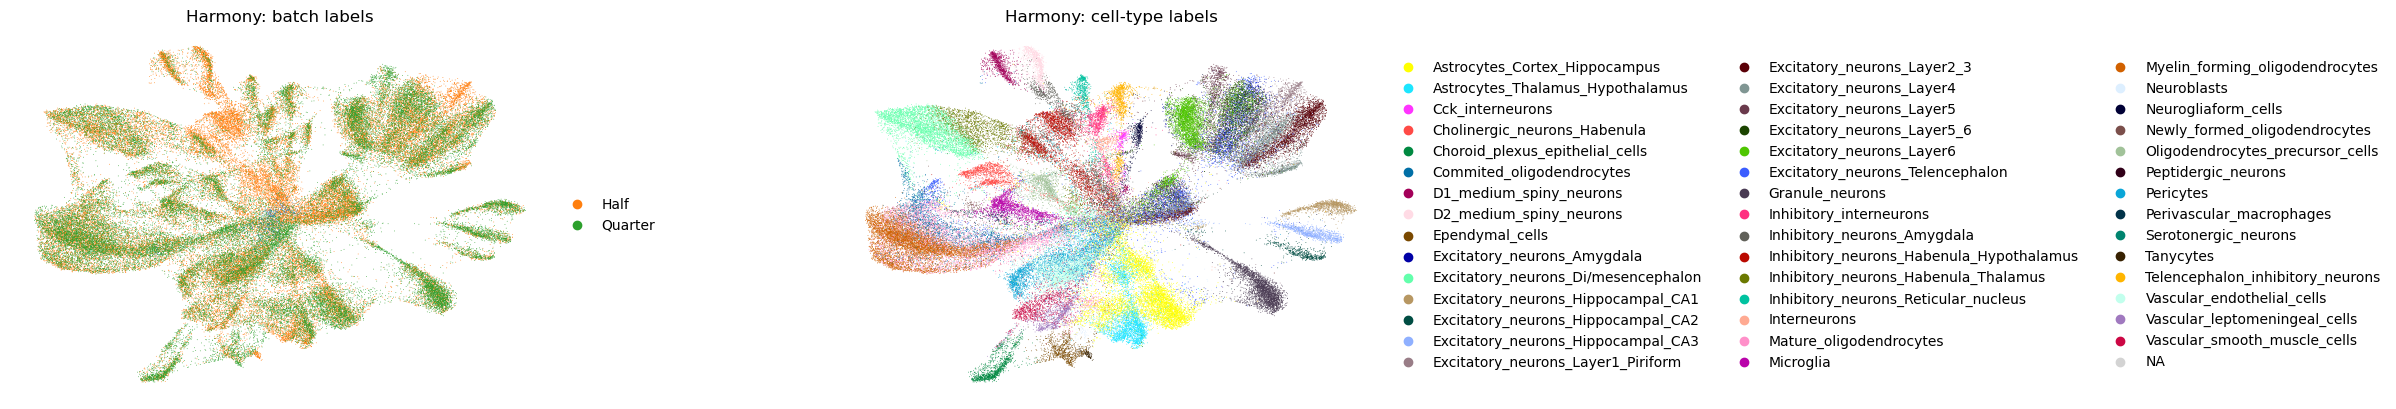

In [23]:
sc.pl.umap(
    adata_gexp_hvg,
    color=["tissue", "cluster_long"],
    wspace=0.4,
    title=["Harmony: batch labels", "Harmony: cell‐type labels"],
    frameon=False,
)

In [24]:
# use NanoString cell_barcode as index (is unique, needed for concat later)
adata_gexp_hvg.obs_names = adata_gexp_hvg.obs["cell_barcode"].astype(str)

In [25]:
adata_gexp_hvg.write(data_dir / "adata_gexp_filtered.h5ad")

## Morphology: Run PyCytoMiner workflow
following https://github.com/scverse/squidpy_notebooks/blob/add_cpmeasure_notebook/tutorials/tutorial_cpmeasure.ipynb

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/scanpy/tools/_utils.py:41: UserWarning: You’re trying to run this on 1739 dimensions of `.X`, if you really want this, set `use_rep='X'`.
         Falling back to preprocessing with `sc.pp.pca` and default params.
  warnings.warn(
/tmp/ipykernel_210740/4278073994.py:5: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_morphology_raw)


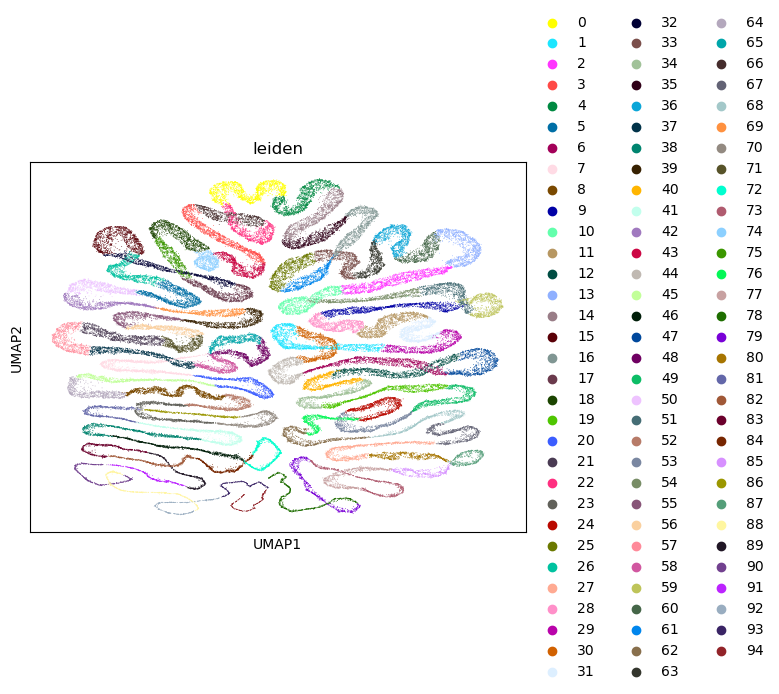

In [26]:
# we expect this to be bad

sc.pp.neighbors(adata_morphology_raw)
sc.tl.umap(adata_morphology_raw)
sc.tl.leiden(adata_morphology_raw)
sc.pl.umap(adata_morphology_raw, color="leiden")

In [27]:
adata_morphology_df = adata_morphology_raw.to_df()

scaler = RobustMAD(epsilon=1e-18)
fitted_scaler = scaler.fit(adata_morphology_df)
fitted_scaled = fitted_scaler.transform(adata_morphology_df)

adata_morphology_df_scaled = pd.DataFrame(
    fitted_scaled,
    columns=adata_morphology_df.columns,
    index=adata_morphology_df.index,
)
adata_morphology_df_scaled

,intensity_mean_0,intensity_min_0,intensity_std_0,intensity_max_0,RadialDistribution_FracAtD_1of4_0,RadialDistribution_MeanFrac_1of4_0,RadialDistribution_RadialCV_1of4_0,RadialDistribution_FracAtD_2of4_0,RadialDistribution_MeanFrac_2of4_0,RadialDistribution_RadialCV_2of4_0,...,intensity_mean_2-1,intensity_min_2-1,intensity_min_3-1,intensity_max_3-1,intensity_std_3-1,intensity_mean_3-1,intensity_max_4-1,intensity_min_4-1,intensity_mean_4-1,intensity_std_4-1
cell_barcode,,,,,,,,,,,,,,,,,,,,,
c_2_1_1,0.873023,0.352835,2.406962,1.794815,-1.440800,-1.283711,1.051780,-0.867437,-0.663140,-0.925807,...,0.096748,-0.024089,0.462327,1.946991,1.670705,1.170884,0.617363,-0.731651,-0.528838,0.052256
c_2_1_2,1.060411,1.321441,1.682648,1.471060,-0.417617,1.374300,-0.866546,0.121965,2.339110,0.083871,...,0.171189,0.072267,0.402161,0.657738,1.269735,1.142365,-0.497775,-0.925996,-0.843425,-0.666986
c_2_1_3,2.692087,1.996451,3.301748,1.957554,0.562399,0.677532,-0.094251,-0.280155,-0.258581,0.315694,...,-0.268450,-0.208771,-0.310329,0.382406,0.237665,-0.290124,-0.003428,-0.880268,-0.759313,-0.425664
c_2_1_4,1.594384,1.688305,1.536626,1.060338,-0.882041,-0.603603,0.540731,0.654135,1.007065,0.896362,...,0.862517,0.184682,0.421161,1.742313,1.186260,0.944874,0.634882,-0.925996,-0.677409,-0.322586
c_2_1_5,1.423434,1.294939,2.545005,1.393995,-0.884534,-0.690597,-0.743550,0.596098,0.778660,-0.522258,...,1.087395,0.144534,0.079166,1.383216,0.800554,0.512611,0.364476,-0.685923,-0.557388,-0.399078
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
c_1_66_710,-0.671765,-0.676569,-0.667061,-0.671621,-1.557305,-1.402899,-0.169263,0.617881,1.345960,-1.563770,...,-0.743413,-0.738728,-0.680824,-0.268048,0.004800,-0.520725,-0.711053,-1.188933,-0.884668,-0.732945
c_1_66_711,-0.675377,-0.673971,-0.676343,-0.678078,-0.911019,-0.696502,-3.310928,0.053228,0.002987,-2.389878,...,-0.675515,-0.666461,-0.715657,-0.717466,-0.713272,-0.762056,-0.828355,-0.800243,-0.882403,-0.840267
c_1_66_712,-0.673210,-0.673451,-0.671628,-0.674204,-0.288487,-0.562092,-0.251167,-0.282945,-0.077462,-0.667834,...,-0.728746,-0.706609,-0.677657,-0.498220,-0.354713,-0.671277,-0.328295,-0.788811,0.575858,0.334492


In [28]:
feature_select_opts = [
    "variance_threshold",
    "drop_na_columns",
    "correlation_threshold",
    "blocklist",
    "drop_outliers",
]

adata_morphology_df_scaled_filtered = pycytominer.feature_select(
    profiles=adata_morphology_df_scaled,
    features=adata_morphology_df_scaled.columns.tolist(),
    samples="all",
    operation=feature_select_opts,
)
adata_morphology_df_scaled_filtered


,RadialDistribution_FracAtD_1of4_0,RadialDistribution_RadialCV_1of4_0,RadialDistribution_FracAtD_2of4_0,RadialDistribution_RadialCV_2of4_0,RadialDistribution_FracAtD_3of4_0,RadialDistribution_RadialCV_3of4_0,RadialDistribution_FracAtD_4of4_0,RadialDistribution_RadialCV_4of4_0,RadialDistribution_ZernikeMagnitude_1_1_0,RadialDistribution_ZernikePhase_1_1_0,...,inertia_tensor_0x0_2_4,inertia_tensor_0x1_2_4,Correlation_Costes_1_2_4,inertia_tensor_eigvals_0_3_4,intensity_mean_0-1,intensity_min_0-1,intensity_max_1-1,intensity_min_3-1,intensity_max_4-1,intensity_min_4-1
cell_barcode,,,,,,,,,,,,,,,,,,,,,
c_2_1_1,-1.440800,1.051780,-0.867437,-0.925807,0.133846,1.308046,2.162681,0.173979,1.906276,-0.952891,...,-1.124845,-0.719717,-0.674491,0.071874,0.873023,0.352835,7.563290,0.462327,0.617363,-0.731651
c_2_1_2,-0.417617,-0.866546,0.121965,0.083871,-0.328626,3.227498,0.628209,1.461215,-0.619657,0.229357,...,-0.544963,-3.984036,163.837131,1.086870,1.060411,1.321441,1.063447,0.402161,-0.497775,-0.925996
c_2_1_3,0.562399,-0.094251,-0.280155,0.315694,-0.375443,-0.195356,0.101763,-0.273413,1.097622,0.675427,...,1.449955,-2.562366,-0.674491,1.027632,2.692087,1.996451,3.514097,-0.310329,-0.003428,-0.880268
c_2_1_4,-0.882041,0.540731,0.654135,0.896362,0.480269,-1.192585,-0.245757,0.788304,-0.127710,0.286884,...,-0.976170,-0.636101,163.837131,0.483202,1.594384,1.688305,6.654975,0.421161,0.634882,-0.925996
c_2_1_5,-0.884534,-0.743550,0.596098,-0.522258,-0.243103,0.031939,0.535800,0.864415,1.643985,1.246163,...,-0.153625,-1.731808,152.831888,0.276469,1.423434,1.294939,7.632987,0.079166,0.364476,-0.685923
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
c_1_66_710,-1.557305,-0.169263,0.617881,-1.563770,-0.235297,-0.459846,1.173602,0.952161,1.797107,-0.210453,...,2.351118,0.797468,163.837131,1.346795,-0.671765,-0.676569,-0.678987,-0.680824,-0.711053,-1.188933
c_1_66_711,-0.911019,-3.310928,0.053228,-2.389878,0.918735,-0.955503,-0.058521,2.365616,-0.928719,0.471748,...,-1.376423,0.319334,163.837131,-1.369389,-0.675377,-0.673971,-0.625028,-0.715657,-0.828355,-0.800243
c_1_66_712,-0.288487,-0.251167,-0.282945,-0.667834,0.205890,-0.282333,0.368496,3.236256,-0.024567,-1.087467,...,-0.537440,-0.627685,163.837131,-0.778956,-0.673210,-0.673451,-0.373218,-0.677657,-0.328295,-0.788811


In [29]:
adata_morphology_filtered = ad.AnnData(
    X=adata_morphology_df_scaled_filtered,
    obs=adata_morphology_raw.obs,
)
del adata_morphology_filtered.obs["leiden"]
adata_morphology_filtered

AnnData object with n_obs × n_vars = 87552 × 328
    obs: 'fov_x', 'cellID', 'global_cell_id', 'x_global_px', 'y_global_px', 'x_local_px', 'y_local_px', 'region', 'cell_barcode', 'cluster', 'cluster_long', 'tissue', 'run_tissue', 'fov_y', 'x_fov_px', 'y_fov_px'

In [30]:
del adata_morphology_filtered.uns["leiden_colors"]

KeyError: 'leiden_colors'

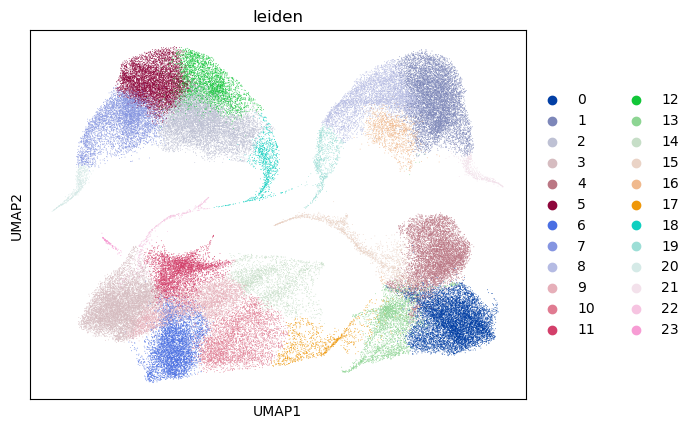

In [ ]:
sc.pp.neighbors(adata_morphology_filtered)
sc.tl.umap(adata_morphology_filtered)
sc.tl.leiden(adata_morphology_filtered)
sc.pl.umap(adata_morphology_filtered, color="leiden")

In [ ]:
adata_morphology_filtered.write(data_dir / "adata_morphology_filtered.h5ad")
adata_morphology_filtered

AnnData object with n_obs × n_vars = 87552 × 328
    obs: 'fov_x', 'cellID', 'global_cell_id', 'x_global_px', 'y_global_px', 'x_local_px', 'y_local_px', 'region', 'cell_barcode', 'cluster', 'cluster_long', 'tissue', 'run_tissue', 'fov_y', 'x_fov_px', 'y_fov_px', 'leiden'
    uns: 'pca', 'neighbors', 'umap', 'leiden', 'leiden_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

### Sanity check as spatial overlay

In [ ]:
adata_for_half = adata_morphology_filtered[adata_morphology_filtered.obs["tissue"] == "Half"].copy()
adata_for_half.uns["spatialdata_attrs"] = sdata_half["gexp"].uns["spatialdata_attrs"]
sdata_half.tables["morph"] = TableModel.parse(adata_for_half)

In [ ]:
del sdata_half.tables["morph"].obs["cell_barcode"]

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:798: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


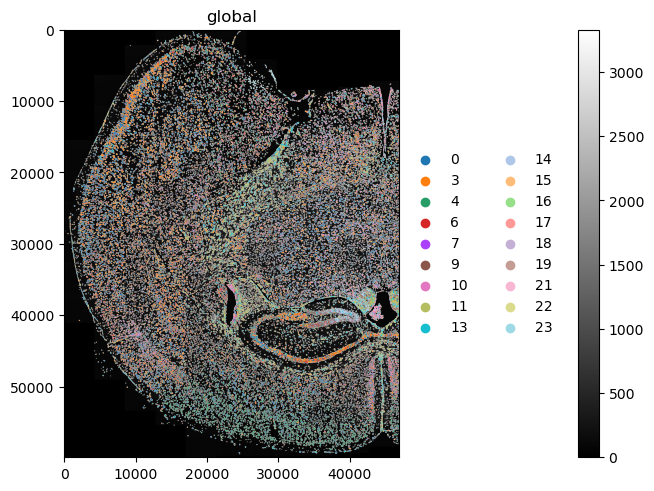

In [ ]:
(
    sdata_half
    .pl.render_images(channel="DNA", scale="scale4", cmap="gray")
    .pl.render_labels(scale="scale4", color="leiden", table_name="morph", outline_alpha=1, fill_alpha=1)
    .pl.show()
)

## Merge and prepare for training

In [ ]:
adata_morphology_filtered

AnnData object with n_obs × n_vars = 87552 × 328
    obs: 'fov_x', 'cellID', 'global_cell_id', 'x_global_px', 'y_global_px', 'x_local_px', 'y_local_px', 'region', 'cell_barcode', 'cluster', 'cluster_long', 'tissue', 'run_tissue', 'fov_y', 'x_fov_px', 'y_fov_px', 'leiden'
    uns: 'pca', 'neighbors', 'umap', 'leiden', 'leiden_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [ ]:
adata_gexp_hvg.to_df()

,Chrna4,Slc6a1,Aldoc,Drd1,Cbln2,Calb2,Sstr4,Hexb,Slc17a7,Nap1l5,...,C1qc,Atp2b1,Zbtb20,Adora2a,Robo1,Prkca,Slc18a2,Camk4,Fa2h,Cck
cell_barcode,,,,,,,,,,,,,,,,,,,,,
c_2_1_1,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.693147,...,1.098612,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.000000
c_2_1_2,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.000000
c_2_1_3,1.791759,0.693147,1.098612,0.000000,0.693147,0.0,0.693147,0.693147,0.0,1.098612,...,0.693147,0.000000,0.000000,0.0,0.693147,0.000000,0.0,0.0,0.000000,0.000000
c_2_1_4,0.693147,0.693147,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.693147,0.0,1.791759,0.000000,0.0,0.0,0.000000,0.693147
c_2_1_5,0.000000,0.000000,1.098612,0.000000,0.000000,0.0,0.693147,0.000000,0.0,0.000000,...,0.000000,0.693147,0.693147,0.0,0.693147,0.693147,0.0,0.0,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
c_1_66_710,0.000000,0.693147,1.609438,0.693147,0.000000,0.0,0.000000,0.000000,0.0,0.000000,...,0.000000,0.693147,0.000000,0.0,0.000000,0.000000,0.0,0.0,1.386294,0.000000
c_1_66_711,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000,...,0.693147,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.000000
c_1_66_712,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.000000


In [ ]:
adata_both = ad.AnnData(
    X=pd.concat([adata_morphology_filtered.to_df(), adata_gexp_hvg.to_df()], axis=1),
    obs=adata_morphology_filtered.obs,
)

### Optionally create more coarse celltype annotation

In [ ]:
fine2coarse_base = {
    "Astrocytes_Cortex_Hippocampus":         "Astrocytes",
    "Astrocytes_Thalamus_Hypothalamus":      "Astrocytes",
    "Cck_interneurons":                      "Inhibitory neurons",
    "Cholinergic_neurons_Habenula":          "Cholinergic neurons",
    "Choroid_plexus_epithelial_cells":       "Epithelial cells",
    "Commited_oligodendrocytes":             "Oligodendrocytes",
    "D1_medium_spiny_neurons":               "Medium spiny neurons",
    "D2_medium_spiny_neurons":               "Medium spiny neurons",
    "Ependymal_cells":                       "Ependymal cells",
    "Excitatory_neurons_Amygdala":           "Excitatory neurons (Amygdala)",
    "Excitatory_neurons_Di/mesencephalon":   "Excitatory neurons (Di/mesencephalon)",
    "Excitatory_neurons_Hippocampal_CA1":    "Excitatory neurons (Hippocampal_CA1)",
    "Excitatory_neurons_Hippocampal_CA2":    "Excitatory neurons (Hippocampal_CA2)",
    "Excitatory_neurons_Hippocampal_CA3":    "Excitatory neurons (Hippocampal_CA3)",
    "Excitatory_neurons_Layer1_Piriform":    "Excitatory neurons (Layer1_Piriform)",
    "Excitatory_neurons_Layer2_3":           "Excitatory neurons (Layer2_3)",
    "Excitatory_neurons_Layer4":             "Excitatory neurons (Layer4)",
    "Excitatory_neurons_Layer5":             "Excitatory neurons (Layer5)",
    "Excitatory_neurons_Layer5_6":           "Excitatory neurons (Layer5_6)",
    "Excitatory_neurons_Layer6":             "Excitatory neurons (Layer6)",
    "Excitatory_neurons_Telencephalon":      "Excitatory neurons (Telencephalon)",
    "Granule_neurons":                       "Granule neurons",
    "Inhibitory_interneurons":               "Inhibitory neurons",
    "Inhibitory_neurons_Amygdala":           "Inhibitory neurons",
    "Inhibitory_neurons_Habenula_Hypothalamus": "Inhibitory neurons",
    "Inhibitory_neurons_Habenula_Thalamus":  "Inhibitory neurons",
    "Inhibitory_neurons_Reticular_nucleus":  "Inhibitory neurons",
    "Interneurons":                          "Inhibitory neurons",
    "Mature_oligodendrocytes":               "Oligodendrocytes",
    "Microglia":                             "Microglia",
    "Myelin_forming_oligodendrocytes":       "Oligodendrocytes",
    "Neuroblasts":                           "Neuroblasts",
    "Neurogliaform_cells":                   "Inhibitory neurons",
    "Newly_formed_oligodendrocytes":         "Oligodendrocytes",
    "Oligodendrocytes_precursor_cells":      "Oligodendrocytes",
    "Peptidergic_neurons":                   "Peptidergic neurons",
    "Pericytes":                             "Pericytes",
    "Perivascular_macrophages":              "Perivascular macrophages",
    "Serotonergic_neurons":                  "Serotonergic neurons",
    "Tanycytes":                             "Ependymal cells",
    "Telencephalon_inhibitory_neurons":      "Inhibitory neurons",
    "Vascular_endothelial_cells":            "Vascular cells",
    "Vascular_leptomeningeal_cells":         "Vascular cells",
    "Vascular_smooth_muscle_cells":          "Vascular cells"
}

In [ ]:
adata_both.obs["celltypes_coarse_base"] = (
    adata_both.obs["cluster_long"]
    .map(fine2coarse_base)
    .fillna("Other")
)

In [ ]:
fine2coarse_medium = {
    # Astrocytes
    "Astrocytes_Cortex_Hippocampus":       "Astrocytes",
    "Astrocytes_Thalamus_Hypothalamus":    "Astrocytes",

    # Oligodendrocyte lineage
    "Oligodendrocytes_precursor_cells":    "Oligodendrocyte precursor cells",
    "Commited_oligodendrocytes":           "Oligodendrocytes",
    "Mature_oligodendrocytes":             "Oligodendrocytes",
    "Myelin_forming_oligodendrocytes":     "Oligodendrocytes",
    "Newly_formed_oligodendrocytes":       "Oligodendrocytes",

    # Epithelial lining
    "Ependymal_cells":                     "Ependymal cells",
    "Tanycytes":                           "Ependymal cells",
    "Choroid_plexus_epithelial_cells":     "Choroid plexus epithelial cells",

    # Immune cells
    "Microglia":                           "Microglia",
    "Perivascular_macrophages":            "Perivascular macrophages",

    # Neural progenitors
    "Neuroblasts":                         "Neuroblasts",

    # Excitatory neurons
    "Excitatory_neurons_Amygdala":         "Excitatory neurons",
    "Excitatory_neurons_Di/mesencephalon": "Excitatory neurons",
    "Excitatory_neurons_Hippocampal_CA1":  "Excitatory neurons",
    "Excitatory_neurons_Hippocampal_CA2":  "Excitatory neurons",
    "Excitatory_neurons_Hippocampal_CA3":  "Excitatory neurons",
    "Excitatory_neurons_Layer1_Piriform":  "Excitatory neurons",
    "Excitatory_neurons_Layer2_3":         "Excitatory neurons",
    "Excitatory_neurons_Layer4":           "Excitatory neurons",
    "Excitatory_neurons_Layer5":           "Excitatory neurons",
    "Excitatory_neurons_Layer5_6":         "Excitatory neurons",
    "Excitatory_neurons_Layer6":           "Excitatory neurons",
    "Excitatory_neurons_Telencephalon":    "Excitatory neurons",

    # Inhibitory neurons
    "Cck_interneurons":                    "Inhibitory neurons",
    "Inhibitory_interneurons":             "Inhibitory neurons",
    "Inhibitory_neurons_Amygdala":         "Inhibitory neurons",
    "Inhibitory_neurons_Habenula_Hypothalamus": "Inhibitory neurons",
    "Inhibitory_neurons_Habenula_Thalamus":     "Inhibitory neurons",
    "Inhibitory_neurons_Reticular_nucleus":     "Inhibitory neurons",
    "Interneurons":                        "Inhibitory neurons",
    "Neurogliaform_cells":                 "Inhibitory neurons",
    "Telencephalon_inhibitory_neurons":    "Inhibitory neurons",

    # Spiny projection neurons
    "D1_medium_spiny_neurons":             "Spiny projection neurons",
    "D2_medium_spiny_neurons":             "Spiny projection neurons",

    # Granule neurons
    "Granule_neurons":                     "Granule neurons",

    # Neuromodulatory neurons
    "Cholinergic_neurons_Habenula":        "Neuromodulatory neurons",
    "Serotonergic_neurons":                "Neuromodulatory neurons",
    "Peptidergic_neurons":                 "Neuromodulatory neurons",

    # Vascular compartment
    "Vascular_endothelial_cells":          "Vascular endothelial cells",
    "Pericytes":                           "Pericytes",
    "Vascular_smooth_muscle_cells":        "Vascular smooth muscle cells",
    "Vascular_leptomeningeal_cells":       "Vascular leptomeningeal cells"
}

In [ ]:
adata_both.obs["celltypes_coarse_medium"] = (
    adata_both.obs["cluster_long"]
    .map(fine2coarse_medium)
    .fillna("Other")
)

In [ ]:
fine2coarse_very = {
    # Glial cells
    "Astrocytes_Cortex_Hippocampus":         "Glia",
    "Astrocytes_Thalamus_Hypothalamus":      "Glia",
    "Commited_oligodendrocytes":             "Glia",
    "Mature_oligodendrocytes":               "Glia",
    "Myelin_forming_oligodendrocytes":       "Glia",
    "Newly_formed_oligodendrocytes":         "Glia",
    "Oligodendrocytes_precursor_cells":      "Glia",

    # Neuronal cells
    "Cck_interneurons":                      "Neurons",
    "Cholinergic_neurons_Habenula":          "Neurons",
    "D1_medium_spiny_neurons":               "Neurons",
    "D2_medium_spiny_neurons":               "Neurons",
    "Excitatory_neurons_Amygdala":           "Neurons",
    "Excitatory_neurons_Di/mesencephalon":   "Neurons",
    "Excitatory_neurons_Hippocampal_CA1":    "Neurons",
    "Excitatory_neurons_Hippocampal_CA2":    "Neurons",
    "Excitatory_neurons_Hippocampal_CA3":    "Neurons",
    "Excitatory_neurons_Layer1_Piriform":    "Neurons",
    "Excitatory_neurons_Layer2_3":           "Neurons",
    "Excitatory_neurons_Layer4":             "Neurons",
    "Excitatory_neurons_Layer5":             "Neurons",
    "Excitatory_neurons_Layer5_6":           "Neurons",
    "Excitatory_neurons_Layer6":             "Neurons",
    "Excitatory_neurons_Telencephalon":      "Neurons",
    "Granule_neurons":                       "Neurons",
    "Inhibitory_interneurons":               "Neurons",
    "Inhibitory_neurons_Amygdala":           "Neurons",
    "Inhibitory_neurons_Habenula_Hypothalamus": "Neurons",
    "Inhibitory_neurons_Habenula_Thalamus":  "Neurons",
    "Inhibitory_neurons_Reticular_nucleus":  "Neurons",
    "Interneurons":                          "Neurons",
    "Neurogliaform_cells":                   "Neurons",
    "Peptidergic_neurons":                   "Neurons",
    "Serotonergic_neurons":                  "Neurons",
    "Telencephalon_inhibitory_neurons":      "Neurons",

    # Immune cells
    "Microglia":                             "Immune cells",
    "Perivascular_macrophages":              "Immune cells",

    # Vascular compartment
    "Pericytes":                             "Vascular cells",
    "Vascular_endothelial_cells":            "Vascular cells",
    "Vascular_leptomeningeal_cells":         "Vascular cells",
    "Vascular_smooth_muscle_cells":          "Vascular cells",

    # Epithelial lining cells
    "Choroid_plexus_epithelial_cells":       "Epithelial cells",
    "Ependymal_cells":                       "Epithelial cells",
    "Tanycytes":                             "Epithelial cells",

    # Neural progenitors
    "Neuroblasts":                           "Neural progenitor cells"
}

In [ ]:
adata_both.obs["celltypes_coarse_very"] = (
    adata_both.obs["cluster_long"]
    .map(fine2coarse_very)
    .fillna("Other")
)

In [ ]:
feat_origins = []

for feat in adata_both.var_names:
    if feat in adata_morphology_filtered.var_names:
        feat_origins.append("morphology")
    elif feat in adata_gexp_hvg.var_names:
        feat_origins.append("gexp")

adata_both.var["feat_type"] = feat_origins

In [ ]:
adata_both

AnnData object with n_obs × n_vars = 87552 × 509
    obs: 'fov_x', 'cellID', 'global_cell_id', 'x_global_px', 'y_global_px', 'x_local_px', 'y_local_px', 'region', 'cell_barcode', 'cluster', 'cluster_long', 'tissue', 'run_tissue', 'fov_y', 'x_fov_px', 'y_fov_px', 'leiden', 'celltypes_coarse_base', 'celltypes_coarse_medium', 'celltypes_coarse_very'
    var: 'feat_type'

## Write to disk for training

In [ ]:
adata_both.write(data_dir / "adata_both_modalities_for_training.h5ad")